# Least-squares fitting

Fit a curve to a set of points by least squares: choose the coefficients that minimize the sum of the squared vertical distances between the points and the curve. This notebook fits a parabola and a line by solving the normal equations, the way the course did it in a spreadsheet, and checks the results against NumPy's `polyfit`.

The goodness of fit is the coefficient of determination, the share of the variation of y that the fitted curve explains:

$$r^2 = \frac{\sum (\hat y_i - \bar y)^2}{\sum (y_i - \bar y)^2}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## A parabola through six points

Fit $y = a_0 + a_1 x + a_2 x^2$. Setting the derivatives of the squared error to zero gives three linear equations, the normal equations:

$$
\begin{aligned}
n\,a_0 + \textstyle\sum x\,a_1 + \sum x^2\,a_2 &= \textstyle\sum y \\
\textstyle\sum x\,a_0 + \sum x^2\,a_1 + \sum x^3\,a_2 &= \textstyle\sum xy \\
\textstyle\sum x^2\,a_0 + \sum x^3\,a_1 + \sum x^4\,a_2 &= \textstyle\sum x^2 y
\end{aligned}
$$

The spreadsheet had one column for each of x, y, xy, x²y, x², x³ and x⁴, and a row of sums.

In [2]:
x = np.array([1.2, 3.1, 4.9, 7.1, 8.6, 9.8])
y = np.array([4.5, 7.0, 7.8, 6.8, 4.5, 2.7])
n = len(x)

A = np.array([
    [n,              x.sum(),        (x**2).sum()],
    [x.sum(),        (x**2).sum(),   (x**3).sum()],
    [(x**2).sum(),   (x**3).sum(),   (x**4).sum()],
])
rhs = np.array([y.sum(), (x * y).sum(), (x**2 * y).sum()])

a0, a1, a2 = np.linalg.solve(A, rhs)
print(f"y = {a0:.4f} + {a1:.4f} x + {a2:.4f} x^2")

y = 2.1892 + 2.2332 x + -0.2244 x^2


`np.polyfit` solves the same least-squares problem. It returns the coefficients from the highest power down, so they come out reversed.

In [3]:
np.polyfit(x, y, deg=2)[::-1].round(4)

array([ 2.1892,  2.2332, -0.2244])

r^2 = 0.9931


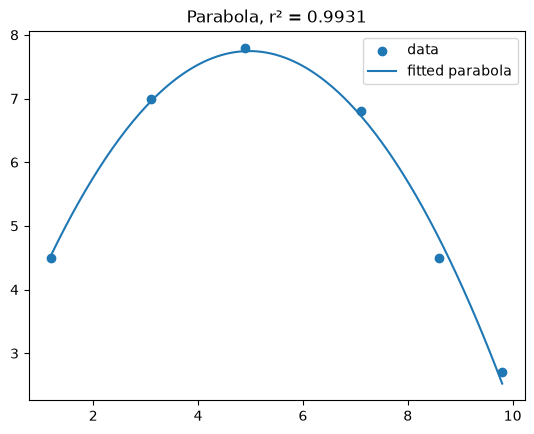

In [4]:
y_hat = a0 + a1 * x + a2 * x**2
r2 = ((y_hat - y.mean())**2).sum() / ((y - y.mean())**2).sum()
print(f"r^2 = {r2:.4f}")

xs = np.linspace(x.min(), x.max(), 200)
plt.scatter(x, y, label="data")
plt.plot(xs, a0 + a1 * xs + a2 * xs**2, label="fitted parabola")
plt.legend()
plt.title(f"Parabola, r² = {r2:.4f}")
plt.show()

The parabola explains 99.3% of the variation of y: the points rise and then fall, and a line could not follow them.

## A line through ten points

For $y = a_0 + a_1 x$ the normal equations have a closed-form solution:

$$a_1 = \frac{n \sum xy - \sum x \sum y}{n \sum x^2 - (\sum x)^2}, \qquad a_0 = \bar y - a_1 \bar x$$

In [5]:
x = np.array([5.12, 6.18, 6.77, 6.65, 6.36, 5.90, 5.48, 6.02, 10.34, 8.51])
y = np.array([2.30, 2.54, 2.95, 3.77, 4.18, 5.31, 5.53, 8.83, 9.48, 14.20])
n = len(x)

a1 = (n * (x * y).sum() - x.sum() * y.sum()) / (n * (x**2).sum() - x.sum()**2)
a0 = y.mean() - a1 * x.mean()
print(f"y = {a0:.4f} + {a1:.4f} x")
print("polyfit:", np.polyfit(x, y, deg=1)[::-1].round(4))

y = -4.7749 + 1.5868 x
polyfit: [-4.7749  1.5868]


r^2 = 0.4221, r = 0.6497


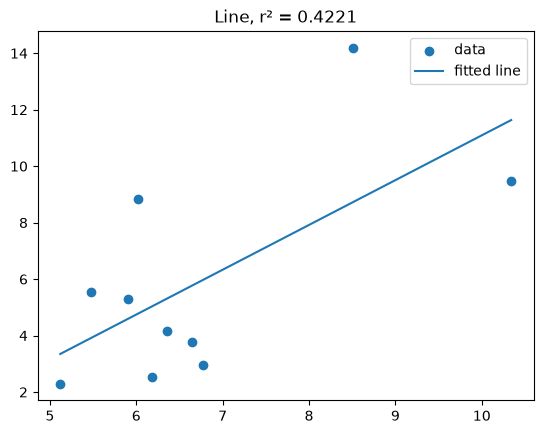

In [6]:
y_hat = a0 + a1 * x
r2 = ((y_hat - y.mean())**2).sum() / ((y - y.mean())**2).sum()
r = np.corrcoef(x, y)[0, 1]
print(f"r^2 = {r2:.4f}, r = {r:.4f}")

xs = np.linspace(x.min(), x.max(), 2)
plt.scatter(x, y, label="data")
plt.plot(xs, a0 + a1 * xs, label="fitted line")
plt.legend()
plt.title(f"Line, r² = {r2:.4f}")
plt.show()

Here the line explains only 42% of the variation. The points with x between 5 and 7 have y values anywhere from 2 to 9, so x alone predicts y poorly. For a line, $r^2$ is the square of the correlation coefficient $r$.

## Notes

- The spreadsheet typed the line's coefficients rounded to two decimals (−4.76 and 1.58 instead of −4.7749 and 1.5868), which gives r² = 0.4185 instead of 0.4221. Rounding coefficients before using them changes the results, so keep full precision until the end.
- The formula for r² above, explained variation over total variation, equals $1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$ only for least-squares fits that include the constant term $a_0$, which both fits here do.